In [18]:
import numpy as np
import pandas as pd
import os
import cv2
from sklearn import metrics
from sklearn.metrics import f1_score, accuracy_score,confusion_matrix,classification_report
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization, Activation
from sklearn.model_selection import train_test_split
from datetime import datetime

In [ ]:
data_dir= "/content/drive/MyDrive/Navegacion autonoma/Webots_Proyecto_final"
Folders=os.listdir(data_dir)
#labels1=pd.read_csv("/content/drive/MyDrive/Navegacion autonoma/Webots_Proyecto_final/Imagenes_Webots_Final_antihorario/registro_sentido_antihorario.csv",header=None,names=["Nombre","Steering"])
#labels2=pd.read_csv("/content/drive/MyDrive/Navegacion autonoma/Webots_Proyecto_final/Imagenes_Webots_Final_horario/registro_sentido_horario.csv",header=None,names=["Nombre","Steering"])
labels3=pd.read_csv("/content/drive/MyDrive/Navegacion autonoma/Webots_Proyecto_final/Imagenes_Webots_Final_newantihorario/registro_sentido_antihorarionew.csv",header=None,names=["Nombre","Steering"])
labels4=pd.read_csv("/content/drive/MyDrive/Navegacion autonoma/Webots_Proyecto_final/Imagenes_Webots_Final_newhorario/registro_sentido_horarionew.csv",header=None,names=["Nombre","Steering"])
labels5=pd.read_csv("/content/drive/MyDrive/Navegacion autonoma/Webots_Proyecto_final/Imagenes_Webots_Final_tiempo_h/registro_tiempo_h.csv",header=None,names=["Nombre","Steering"])
labels6=pd.read_csv("/content/drive/MyDrive/Navegacion autonoma/Webots_Proyecto_final/Imagenes_Webots_Final_tiempo_anti/registro_tiempo_h.csv",header=None,names=["Nombre","Steering"])


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
Lista=pd.concat([labels5,labels6,labels3,labels4],axis=0,ignore_index=True)


In [ ]:
len(Lista)

31107

In [ ]:
imagenanti=labels5["Nombre"].values
imagenhora=labels6["Nombre"].values
imagenantinew=labels3["Nombre"].values
imagenhoranew=labels4["Nombre"].values



In [ ]:
print(len(imagenhora))
print(len(imagenanti))
print(len(imagenantinew))
print(len(imagenhoranew))

13455
12465
2454
2733


array([[[167, 125, 106],
        [166, 124, 105],
        [166, 124, 105],
        ...,
        [ 64,  41,  31],
        [ 69,  44,  32],
        [ 65,  42,  32]],

       [[167, 125, 106],
        [167, 125, 106],
        [166, 124, 105],
        ...,
        [ 62,  40,  31],
        [ 68,  43,  33],
        [ 64,  41,  31]],

       [[167, 125, 106],
        [167, 125, 106],
        [167, 125, 106],
        ...,
        [ 60,  39,  30],
        [ 65,  42,  32],
        [ 62,  40,  31]],

       ...,

       [[ 69,  67,  66],
        [ 69,  66,  66],
        [ 69,  67,  66],
        ...,
        [ 52,  49,  48],
        [ 51,  48,  47],
        [ 50,  47,  46]],

       [[ 66,  63,  63],
        [ 69,  66,  66],
        [ 68,  66,  65],
        ...,
        [ 51,  48,  47],
        [ 50,  47,  46],
        [ 53,  50,  49]],

       [[ 70,  67,  66],
        [ 67,  64,  64],
        [ 68,  65,  65],
        ...,
        [ 52,  49,  48],
        [ 53,  50,  49],
        [ 53,  50,  49]]], dtype=uint8)
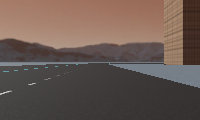

In [ ]:
imagen=cv2.imread("/content/drive/MyDrive/Navegacion autonoma/Webots_Proyecto_final/Imagenes_Webots_Final_newantihorario/camera_central_newa000007.png")
imagen


array([[[82, 74, 80],
        [80, 72, 78],
        [76, 72, 75],
        ...,
        [62, 42, 34],
        [63, 43, 34],
        [64, 43, 34]],

       [[80, 71, 76],
        [79, 70, 75],
        [76, 74, 77],
        ...,
        [63, 43, 34],
        [64, 43, 34],
        [64, 43, 34]],

       [[71, 64, 66],
        [70, 63, 65],
        [73, 68, 70],
        ...,
        [60, 40, 32],
        [61, 41, 32],
        [62, 42, 33]],

       ...,

       [[69, 67, 66],
        [69, 66, 66],
        [69, 67, 66],
        ...,
        [52, 49, 48],
        [51, 48, 47],
        [50, 47, 46]],

       [[66, 63, 63],
        [69, 66, 66],
        [68, 66, 65],
        ...,
        [51, 48, 47],
        [50, 47, 46],
        [53, 50, 49]],

       [[70, 67, 66],
        [67, 64, 64],
        [68, 65, 65],
        ...,
        [52, 49, 48],
        [53, 50, 49],
        [53, 50, 49]]], dtype=uint8)
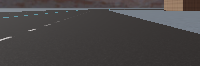

In [ ]:
recorte=imagen[54:120, :, :]
recorte

In [11]:
listaimagenes=[]
Steering=[]
for folder in Folders:
  folderpath = os.path.join(data_dir, folder)
  nombre=os.listdir(folderpath)
  print(len(nombre))
  for imagen in nombre:
    imagenpath = os.path.join(folderpath, imagen)
    image = cv2.imread(imagenpath)
    if image is None:  # Check if the image was loaded successfully
        print(f"Warning: Could not read image file: {imagenpath}")
        continue  # Skip to the next file if the image could not be read
    image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # if image.shape[0] == 66:
    #   recorte=image[32:66, :, :]
    #   image = cv2.resize(recorte, (200, 66))
    # else:
    #   recorte=image[54:120, :, :]
    #   image = cv2.resize(recorte, (200, 66))

    # image = np.array(image)
    recorte = image[54:120] if image.shape[0] != 66 else image[32:66]
    image = cv2.resize(recorte, (200, 66))
    image = image / 255.0  # Normalización
    image = np.expand_dims(image, axis=-1)

    angulo=Lista[Lista["Nombre"]== imagen]["Steering"].values
    if len(angulo) > 0:
      listaimagenes.append(image)
      Steering.append(float(angulo[0]))
    else:
      print(f"Warning: No steering angle found for image: {imagen}")
    #Steering.append(float(angulo[0]))
imagenes=np.array(listaimagenes)
steering=np.array(Steering)

2455
2734
12466
13456


In [13]:
print("imagenes: ",imagenes.shape)
print("labels: ", steering.shape)

X_train, X_test, y_train, y_test = train_test_split(imagenes, steering, test_size=0.2, random_state=42)

print("Xtrain: ",X_train.shape)
print("Xtest: ",X_test.shape)
print("ytrain: ",y_train.shape)
print("ytest: ",y_test.shape)

imagenes:  (31107, 66, 200, 1)
labels:  (31107,)
Xtrain:  (24885, 66, 200, 1)
Xtest:  (6222, 66, 200, 1)
ytrain:  (24885,)
ytest:  (6222,)


In [14]:
def construir_modelo_new():
    modelo = Sequential([
        Conv2D(24, (5, 5), strides=(2, 2), input_shape=(66, 200, 1)),
        BatchNormalization(),
        Activation('relu'),

        Conv2D(36, (5, 5), strides=(2, 2)),
        BatchNormalization(),
        Activation('relu'),

        Conv2D(48, (5, 5), strides=(2, 2)),
        BatchNormalization(),
        Activation('relu'),

        Conv2D(64, (3, 3)),
        BatchNormalization(),
        Activation('relu'),

        Dropout(0.25),

        Conv2D(64, (3, 3)),
        BatchNormalization(),
        Activation('relu'),

        Flatten(),

        Dense(1164),
        BatchNormalization(),
        Activation('relu'),
        Dropout(0.5),

        Dense(100),
        BatchNormalization(),
        Activation('relu'),

        Dense(50),
        BatchNormalization(),
        Activation('relu'),

        Dense(10),
        BatchNormalization(),
        Activation('relu'),

        Dense(1)  # Salida regresiva
    ])
    modelo.compile(optimizer='adam', loss='mse')
    return modelo

modelo = construir_modelo_new()
modelo.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 31, 98, 24)     │           624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 31, 98, 24)     │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 31, 98, 24)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 47, 36)     │        21,636 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 47, 36)     │           144 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 14, 47, 36)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 5, 22, 48)      │        43,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 5, 22, 48)      │           192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 5, 22, 48)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 3, 20, 64)      │        27,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 3, 20, 64)      │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 3, 20, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 3, 20, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 1, 18, 64)      │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 1, 18, 64)      │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 1, 18, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1164)           │     1,342,092 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 1164)           │         4,656 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 1164)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1164)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │       116,50

 Total params: 1,600,551 (6.11 MB)

 Trainable params: 1,597,431 (6.09 MB)

 Non-trainable params: 3,120 (12.19 KB)

In [15]:
historial=modelo.fit(X_train,y_train,epochs=30, batch_size=128,validation_split=0.1)

Epoch 1/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 33s 99ms/step - loss: 0.0913 - val_loss: 0.0081
Epoch 2/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0040 - val_loss: 0.0054
Epoch 3/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0031 - val_loss: 0.0034
Epoch 4/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0024 - val_loss: 0.0013
Epoch 5/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0020 - val_loss: 9.6015e-04
Epoch 6/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0016 - val_loss: 9.9222e-04
Epoch 7/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0016 - val_loss: 8.2395e-04
Epoch 8/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0012 - val_loss: 7.7759e-04
Epoch 9/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0012 - val_loss: 8.6752e-04
Epoch 10/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0011 - val_loss: 7.1199e-04
Epoch 11/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 9.1345e-04 - val_loss: 7.3231e-04
Epoch 12/30
175/17

In [16]:
loss=modelo.evaluate(X_test,y_test)
print("loss: ",loss)

195/195 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 2.6327e-04
loss:  0.00025215340428985655


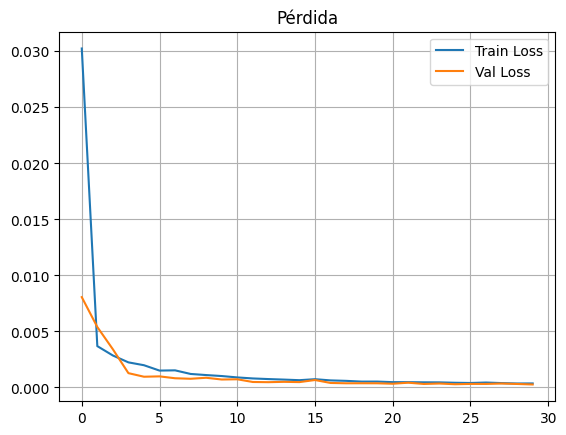

In [17]:
plt.plot(historial.history['loss'], label='Train Loss')
plt.plot(historial.history['val_loss'], label='Val Loss')
plt.legend(); plt.title("Pérdida")
plt.grid()
plt.show()

In [20]:
# Guardado del modelo
timestamp = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
output_path = f"/content/drive/MyDrive/MNA-V/Navegacion/Proyecto final/Models/Modelo_{timestamp}.keras"
modelo.save(output_path)
print("Modelo guardado en:", output_path)

Modelo guardado en: /content/drive/MyDrive/MNA-V/Navegacion/Proyecto final/Models/Modelo_2025-06-22_12-32-00.keras
